<a href="https://colab.research.google.com/github/taniasahu/Deep-Learning-Based-RFF-for-Cross-Day-and-Cross-Receiver-Transmitter-Identification/blob/main/CNN_RFF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import os
import h5py
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers, regularizers

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    f1_score
)

Reproducibility

In [ ]:
SEED = 0
np.random.seed(SEED)
tf.random.set_seed(SEED)

Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

DATA_DIR = "/content/drive/MyDrive/processed"

print(os.listdir(DATA_DIR))

Mounted at /content/drive
['train.mat', 'val.mat', 'test.mat', 'WiSigCNN_best.keras']


Data Loading

In [ ]:
def load_mat_data(file_path, xname, yname):
    with h5py.File(file_path, "r") as f:
        X = np.array(f[xname]).T
        Y = np.array(f[yname]).squeeze()

    X = X.astype(np.float32)
    Y = Y.astype(np.int64) - 1

    return X, Y


X_train, Y_train = load_mat_data(os.path.join(DATA_DIR, "train.mat"),"X_train","Y_train_num")
X_val, Y_val = load_mat_data(os.path.join(DATA_DIR, "val.mat"),"X_val","Y_val_num")
X_test, Y_test = load_mat_data(os.path.join(DATA_DIR, "test.mat"),"X_test","Y_test_num")

print("Train:", X_train.shape, Y_train.shape)
print("Val  :", X_val.shape, Y_val.shape)
print("Test :", X_test.shape, Y_test.shape)

Train: (144000, 512) (144000,)
Val  : (72000, 512) (72000,)
Test : (72000, 512) (72000,)


Convert 512 features into (N samples,256,2)

In [ ]:
def prepare_wisig_input(X):

    I = X[:, :256]
    Q = X[:, 256:]

    X = np.stack([I, Q], axis=-1)

    return X.astype(np.float32)


X_train = prepare_wisig_input(X_train)
X_val   = prepare_wisig_input(X_val)
X_test  = prepare_wisig_input(X_test)

print("After conversion:")
print("Train:", X_train.shape)
print("Val  :", X_val.shape)
print("Test :", X_test.shape)

After conversion:
Train: (144000, 256, 2)
Val  : (72000, 256, 2)
Test : (72000, 256, 2)


Inspection of Data Quality

In [ ]:
print("NaN values:")
print("Train:", np.isnan(X_train).sum())
print("Val  :", np.isnan(X_val).sum())
print("Test :", np.isnan(X_test).sum())

print("\nInf values:")
print("Train:", np.isinf(X_train).sum())
print("Val  :", np.isinf(X_val).sum())
print("Test :", np.isinf(X_test).sum())

NaN values:
Train: 0
Val  : 0
Test : 0

Inf values:
Train: 0
Val  : 0
Test : 0


Number of Classes

In [ ]:
NUM_CLASSES = 6

class_names = [
    "14-10",
    "14-7",
    "20-15",
    "20-19",
    "6-15",
    "8-20"
]

print("Number of classes:", NUM_CLASSES)
print("Classes:", class_names)

Number of classes: 6
Classes: ['14-10', '14-7', '20-15', '20-19', '6-15', '8-20']


Convert labels into One Hot Labels

In [ ]:
Y_train_cat = tf.keras.utils.to_categorical( Y_train,NUM_CLASSES)
Y_val_cat = tf.keras.utils.to_categorical(Y_val,NUM_CLASSES)
Y_test_cat = tf.keras.utils.to_categorical(Y_test,NUM_CLASSES)

print("Train labels:", Y_train_cat.shape)
print("Val labels  :", Y_val_cat.shape)
print("Test labels :", Y_test_cat.shape)

Train labels: (144000, 6)
Val labels  : (72000, 6)
Test labels : (72000, 6)


Class Distribution

In [ ]:
print("\nTraining class distribution:")

for i, name in enumerate(class_names):
    print(
        f"Class {i} ({name}):",
        np.sum(Y_train == i)
    )


Training class distribution:
Class 0 (14-10): 24000
Class 1 (14-7): 24000
Class 2 (20-15): 24000
Class 3 (20-19): 24000
Class 4 (6-15): 24000
Class 5 (8-20): 24000


CNN pipeline

In [ ]:
def create_wisig_cnn():

    inputs = keras.Input(shape=(256, 2))

    x = layers.Reshape((256, 2, 1))(inputs)
    x = layers.Conv2D(8,(3, 2),activation="relu",padding="same")(x)
    x = layers.MaxPool2D((2, 1))(x)
    x = layers.Conv2D(16,(3, 2),activation="relu",padding="same")(x)
    x = layers.MaxPool2D((2, 1))(x)
    x = layers.Conv2D(16,(3, 2),activation="relu",padding="same")(x)
    x = layers.MaxPool2D((2, 2))(x)
    x = layers.Conv2D(32,(3, 1),activation="relu",padding="same")(x)
    x = layers.MaxPool2D((2, 1))(x)
    x = layers.Conv2D(16,(3, 1),activation="relu",padding="same")(x)
    x = layers.Flatten()(x)
    x = layers.Dense(100,activation="relu",kernel_regularizer=regularizers.l2(0.0001))(x)
    x = layers.Dense(80,activation="relu",kernel_regularizer=regularizers.l2(0.0001))(x)
    x = layers.Dropout(0.5)(x)

    outputs = layers.Dense(NUM_CLASSES,activation="softmax",kernel_regularizer=regularizers.l2(0.0001))(x)

    model = keras.Model(inputs=inputs,outputs=outputs)

    return model

model = create_wisig_cnn()
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 2)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 256, 2, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 256, 2, 8)      │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 128, 2, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 2, 16)     │           784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 64, 2, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 2, 16)      │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 32, 1, 16)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 32, 1, 32)      │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 16, 1, 32)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 1, 16)      │         1,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 100)            │        25,700 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 80)             │         8,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 6)              │           486 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,778 (155.38 KB)

 Trainable params: 39,778 (155.38 KB)

 Non-trainable params: 0 (0.00 B)

Compile the Model

In [ ]:
model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.0005),
    loss="categorical_crossentropy",
    metrics=["categorical_accuracy"])

Callbacks

In [ ]:
checkpoint_path = os.path.join(DATA_DIR,"WiSigCNN_best.keras")
checkpoint = keras.callbacks.ModelCheckpoint(checkpoint_path,monitor="val_loss",save_best_only=True,verbose=1)
early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss",patience=5,restore_best_weights=True,verbose=1)

Train

In [ ]:
history = model.fit(
    X_train,
    Y_train_cat,

    validation_data=(
        X_val,
        Y_val_cat
    ),

    epochs=100,
    batch_size=32,

    callbacks=[
        checkpoint,
        early_stopping
    ],

    verbose=1
)

Epoch 1/100
4500/4500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.8015 - loss: 0.5079
Epoch 1: val_loss improved from None to 0.30502, saving model to /content/drive/MyDrive/processed/WiSigCNN_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/processed/WiSigCNN_best.keras
4500/4500 ━━━━━━━━━━━━━━━━━━━━ 42s 7ms/step - categorical_accuracy: 0.9055 - loss: 0.2591 - val_categorical_accuracy: 0.8917 - val_loss: 0.3050
Epoch 2/100
4497/4500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.9739 - loss: 0.0907
Epoch 2: val_loss did not improve from 0.30502
4500/4500 ━━━━━━━━━━━━━━━━━━━━ 25s 6ms/step - categorical_accuracy: 0.9768 - loss: 0.0825 - val_categorical_accuracy: 0.9223 - val_loss: 0.3118
Epoch 3/100
4490/4500 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - categorical_accuracy: 0.9821 - loss: 0.0678
Epoch 3: val_loss did not improve from 0.30502
4500/4500 ━━━━━━━━━━━━━━━━━━━━ 25s 6ms/step - categorical_accuracy: 0.9835 - loss: 0.0635 - val_categorical_a

Load Best Model

In [ ]:
model = keras.models.load_model(checkpoint_path)
print("Best CNN model loaded.")

Best CNN model loaded.


Evaluate Validation Set

In [ ]:
val_loss, val_acc = model.evaluate(X_val,Y_val_cat,batch_size=32,verbose=1)

print("\nValidation Results")
print("Validation Loss     :", val_loss)
print("Validation Accuracy :", val_acc)

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - categorical_accuracy: 0.9356 - loss: 0.2387

Validation Results
Validation Loss     : 0.23872235417366028
Validation Accuracy : 0.9356250166893005


Evaluate Test Set

In [ ]:
test_loss, test_acc = model.evaluate(
    X_test,
    Y_test_cat,
    batch_size=32,
    verbose=1
)

print("\nTest Results")
print("Test Loss     :", test_loss)
print("Test Accuracy :", test_acc)

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - categorical_accuracy: 0.8923 - loss: 0.5425

Test Results
Test Loss     : 0.542538046836853
Test Accuracy : 0.8923472166061401


Generate Predictions

In [ ]:
probabilities = model.predict(
    X_test,
    batch_size=32,
    verbose=1)

predictions = np.argmax(probabilities,axis=1)

2250/2250 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step


Accuracy + F1 Scores

In [ ]:
accuracy = accuracy_score(Y_test,predictions)
macro_f1 = f1_score(Y_test,predictions,average="macro")
weighted_f1 = f1_score(Y_test,predictions,average="weighted")

print("FINAL TEST RESULTS")
print(f"Accuracy   : {accuracy:.4f}")
print(f"Macro F1   : {macro_f1:.4f}")
print(f"Weighted F1: {weighted_f1:.4f}")

FINAL TEST RESULTS
Accuracy   : 0.8923
Macro F1   : 0.8914
Weighted F1: 0.8914


Classification Report

In [ ]:
import matplotlib.pyplot as plt
print("\nClassification Report")
print(classification_report(
        Y_test,
        predictions,
        target_names=class_names,
        digits=4
    ))


Classification Report
              precision    recall  f1-score   support

       14-10     0.9461    0.9802    0.9629     12000
        14-7     0.8021    0.6810    0.7366     12000
       20-15     0.9101    0.9819    0.9446     12000
       20-19     0.7301    0.8141    0.7698     12000
        6-15     0.9811    0.9886    0.9848     12000
        8-20     0.9943    0.9083    0.9493     12000

    accuracy                         0.8923     72000
   macro avg     0.8940    0.8923    0.8914     72000
weighted avg     0.8940    0.8923    0.8914     72000



Confusion Matrix

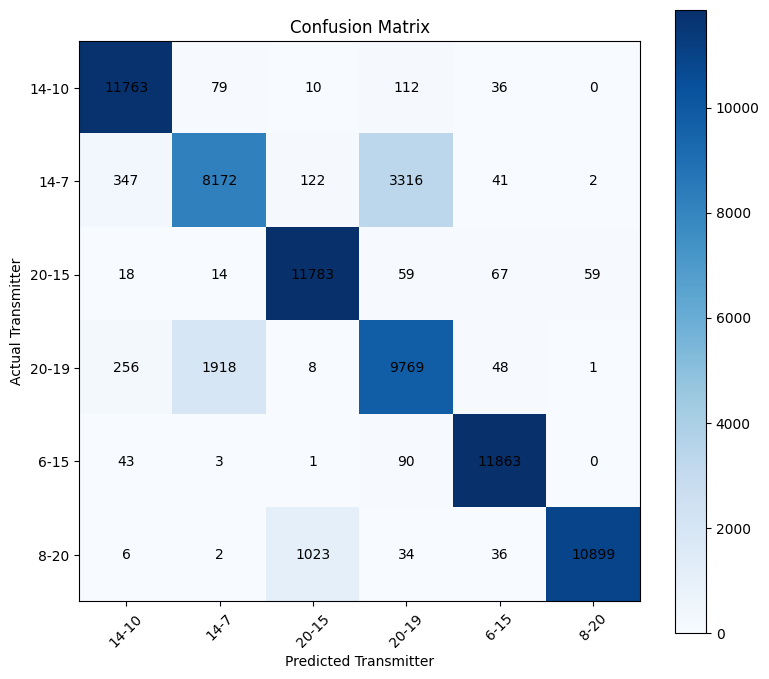

In [ ]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(Y_test, predictions)
plt.figure(figsize=(8, 7))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.title("Confusion Matrix")
plt.xlabel("Predicted Transmitter")
plt.ylabel("Actual Transmitter")

plt.xticks(range(NUM_CLASSES),class_names,rotation=45)
plt.yticks(range(NUM_CLASSES),class_names)

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(j,i,
            cm[i, j],
            ha="center",
            va="center",
            color="black")

plt.tight_layout()
plt.show()